# **Healthcare Cost Prediction and Patient Segmentation Using Machine Learning**

## **Project Overview**

This project develops a machine learning workflow for predicting individual healthcare costs and segmenting patients into meaningful groups.

The project covers data preprocessing, missing-value handling, categorical encoding, feature scaling, regression modeling, regression assumptions, polynomial regression, regularization, model evaluation, and unsupervised patient segmentation.

The main prediction target is **healthcare cost (`charges`)**, while clustering is used to identify groups of patients with similar demographic, lifestyle, and healthcare-cost characteristics.

## **Table of Contents**

1. [Project Introduction](#1-project-introduction)
2. [Business Problem and Objectives](#2-business-problem-and-objectives)
3. [Dataset Description](#3-dataset-description)
4. [Import Libraries](#4-import-libraries)
5. [Load Dataset](#5-load-dataset)
6. [Initial Data Understanding](#6-initial-data-understanding)
7. [Identify Features and Target](#7-identify-features-and-target)
8. [Exploratory Data Analysis](#8-exploratory-data-analysis)
9. [Part 1 — Data Preprocessing](#9-part-1--data-preprocessing)
   - Missing Values
   - Basic Imputation
   - Advanced Imputation
   - Categorical Encoding
   - Inverse Transformation
   - Feature Scaling
10. [Train-Test Split](#10-train-test-split)
11. [Part 2 — Regression Modeling](#11-part-2--regression-modeling)
    - Simple Linear Regression
    - Multiple Linear Regression
    - Linear Regression Assumptions
    - Relationship Analysis
    - Polynomial Regression
12. [Part 3 — Regularization](#12-part-3--regularization)
    - Ridge Regression
    - Lasso Regression
    - Overfitting and Performance Comparison
13. [Part 4 — Model Evaluation](#13-part-4--model-evaluation)
14. [Regression Model Comparison](#14-regression-model-comparison)
15. [Best Regression Model](#15-best-regression-model)
16. [Part 5 — Patient Segmentation](#16-part-5--patient-segmentation)
    - K-Means Clustering
    - Optimal Number of Clusters
    - Hierarchical Clustering
    - Clustering Comparison
17. [Part 6 — Insights and Interpretation](#17-part-6--insights-and-interpretation)
18. [Final Conclusions](#18-final-conclusions)

# **Project Introduction**

Healthcare costs vary considerably between individuals because of differences in age, body characteristics, lifestyle factors, family responsibilities, and geographic region.

In this project, machine learning is used to solve two related problems:

**1. Healthcare Cost Prediction** — predict an individual's medical insurance charges using demographic and lifestyle features.

**2. Patient Segmentation** — group patients into meaningful clusters based on their characteristics and healthcare costs.

The project follows a complete data science workflow, starting from raw data loading and preprocessing and ending with model comparison, clustering, and actionable insights.

The dataset used in this project is the Medical Cost Personal Dataset, which contains 1,338 observations and seven variables: age, sex, BMI, children, smoker, region, and charges. :contentReference[oaicite:2]{index=2}

# **Business Problem and Objectives**

## **Business Problem**

Insurance organizations need reliable estimates of healthcare costs to understand financial risk and improve cost planning.

At the same time, patients are not homogeneous. Different groups may have different demographic characteristics, lifestyle profiles, and healthcare costs.

Therefore, this project addresses both prediction and segmentation.

## **Project Objectives**

- Identify the important features associated with healthcare costs.
- Handle missing values using basic and advanced imputation techniques.
- Encode categorical variables appropriately.
- Scale numerical features where required.
- Build simple and multiple linear regression models.
- Check important assumptions of linear regression.
- Analyze relationships between variables.
- Build and compare polynomial regression with linear regression.
- Apply Ridge and Lasso regularization.
- Compare regression models using appropriate evaluation metrics.
- Apply K-Means clustering for patient segmentation.
- Determine an appropriate number of clusters.
- Apply hierarchical clustering.
- Compare clustering approaches.
- Identify characteristics of high-cost patient groups.
- Generate data-driven real-world insights.

# **Dataset Description**

## **Dataset**

The project uses the **Medical Cost Personal Dataset**.

### **Variables**

| Variable | Type | Description |
|---|---|---|
| `age` | Numerical | Age of the primary beneficiary |
| `sex` | Categorical | Sex of the beneficiary |
| `bmi` | Numerical | Body Mass Index |
| `children` | Numerical | Number of dependents covered |
| `smoker` | Categorical | Smoking status |
| `region` | Categorical | Residential region |
| `charges` | Numerical | Individual medical costs billed by insurance |

The target variable is **`charges`**.

The remaining variables are used as predictor features. The dataset description confirms these seven variables and 1,338 observations. :contentReference[oaicite:3]{index=3}

# **Import Libraries**

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# **Load Dataset**

The dataset is loaded directly from the project's data folder.

The loading logic automatically identifies the CSV file so that the notebook remains portable and does not depend on a hard-coded filename.

In [4]:
df = pd.read_csv("insurance.csv")  

# Initial Data Understanding

Before preprocessing, the dataset is inspected to understand its structure, data types, dimensions, and statistical characteristics.

In [5]:
display(df.head())
display(df.info())
display(df.describe(include="all").T)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,1338.0,NaN,NaN,NaN,39.207025,14.04996,18.0,27.0,39.0,51.0,64.0
sex,1338,2,male,676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,1338.0,NaN,NaN,NaN,30.663397,6.098187,15.96,26.29625,30.4,34.69375,53.13
children,1338.0,NaN,NaN,NaN,1.094918,1.205493,0.0,0.0,1.0,2.0,5.0
smoker,1338,2,no,1064,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1338,4,southeast,364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charges,1338.0,NaN,NaN,NaN,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


# **Identify Features and Target**

The prediction target is `charges`, representing individual medical costs billed by insurance.

All remaining columns are treated as predictor variables.

In [6]:
target = "charges"
X = df.drop(columns=target)
y = df[target]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Target:", target)
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Target: charges
Numerical features: ['age', 'bmi', 'children']
Categorical features: ['sex', 'smoker', 'region']


# **Exploratory Data Analysis**

Exploratory analysis is performed to understand distributions, categorical frequencies, relationships, and potential outliers before modeling.

In [7]:
print("Shape:", df.shape)
print("\nMissing values:")
display(df.isna().sum().to_frame("missing"))

print("\nDuplicate rows:", df.duplicated().sum())

Shape: (1338, 7)

Missing values:


,missing
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0



Duplicate rows: 1


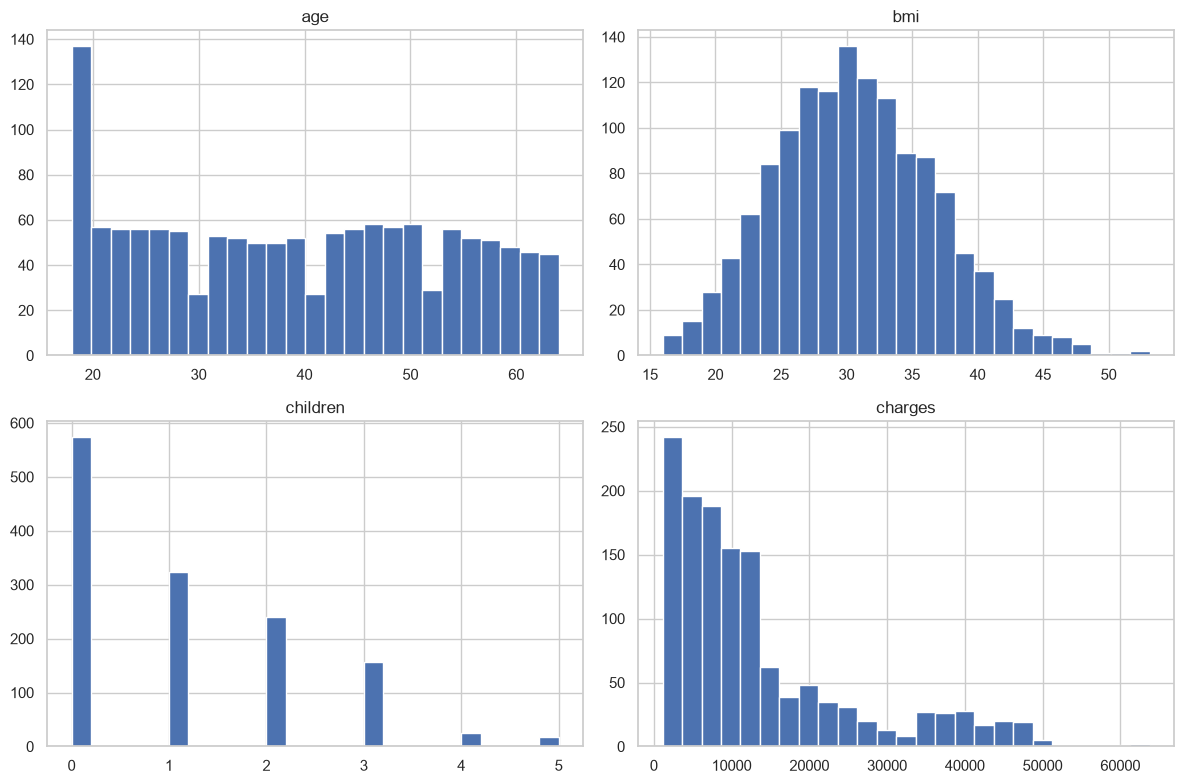

In [8]:
df[numeric_features + [target]].hist(figsize=(12, 8), bins=25)
plt.tight_layout()
plt.show()

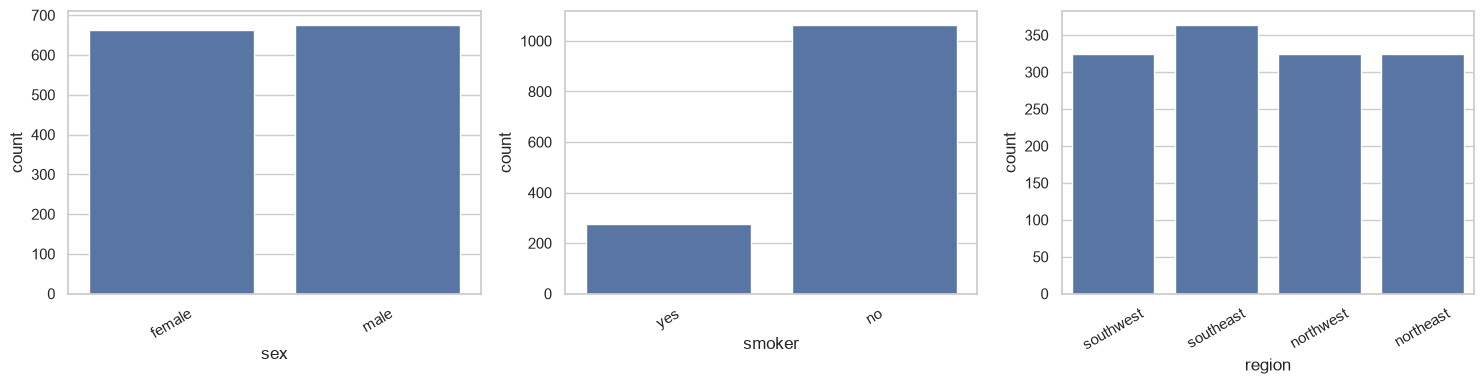

In [9]:
fig, axes = plt.subplots(1, len(categorical_features), figsize=(15, 4))

for ax, col in zip(axes, categorical_features):
    sns.countplot(data=df, x=col, ax=ax)
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

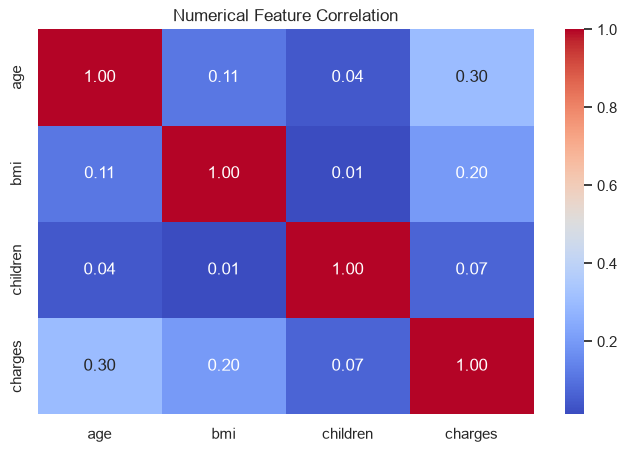

In [10]:
plt.figure(figsize=(8, 5))
sns.heatmap(df.select_dtypes(include=np.number).corr(),
            annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Numerical Feature Correlation")
plt.show()

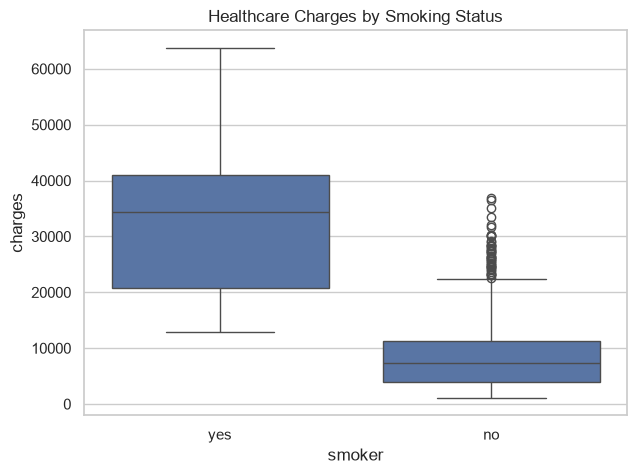

In [11]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="smoker", y="charges")
plt.title("Healthcare Charges by Smoking Status")
plt.show()

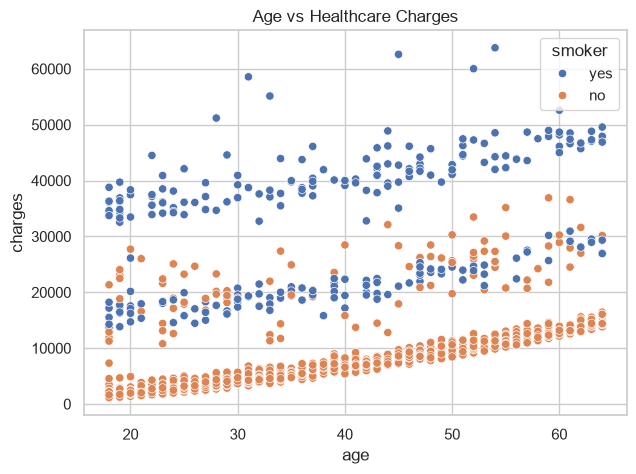

In [12]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="age", y="charges", hue="smoker")
plt.title("Age vs Healthcare Charges")
plt.show()

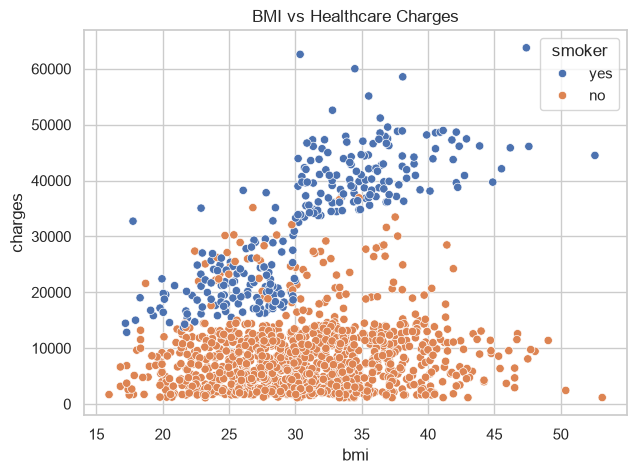

In [13]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker")
plt.title("BMI vs Healthcare Charges")
plt.show()

# **Part 1. Data Preprocessing**

Data preprocessing is required before machine learning because the dataset contains both numerical and categorical variables.

The preprocessing workflow includes:

- Missing-value analysis
- Basic imputation
- Advanced imputation
- Categorical encoding
- Inverse transformation
- Feature scaling

The transformations are placed inside pipelines to reduce data leakage and ensure that preprocessing is learned only from the training data.

## **1. Handle Missing Values**

Missing values are checked before modeling.

Two approaches are considered:

1. **Basic imputation** using median/mode.
2. **Advanced numerical imputation** using KNN-based imputation.

If the original dataset contains no missing values, the imputers still provide a robust preprocessing pipeline for future versions of the data.

In [14]:
missing = df.isna().sum()
display(missing.to_frame("Missing Values"))

print("Total missing values:", missing.sum())

,Missing Values
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


Total missing values: 0


In [15]:
basic_preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", SimpleImputer(strategy="most_frequent"), categorical_features)
])

X_basic = basic_preprocessor.fit_transform(X)

print("Basic imputation completed.")

Basic imputation completed.


## **2. Advanced Imputation**

KNN imputation estimates missing numerical values using information from similar observations.

This provides a more data-driven alternative to replacing every missing numerical value with a single central statistic.

In [16]:
advanced_preprocessor = ColumnTransformer([
    ("num", KNNImputer(n_neighbors=5), numeric_features),
    ("cat", SimpleImputer(strategy="most_frequent"), categorical_features)
])

X_advanced = advanced_preprocessor.fit_transform(X)

print("Advanced KNN imputation completed.")

Advanced KNN imputation completed.


## **3. Encode Categorical Variables**

Categorical variables cannot be directly used by most regression algorithms.

One-hot encoding converts each category into a binary feature while avoiding an artificial numerical ordering between categories.

The encoder also uses `handle_unknown="ignore"` so that unseen categories in future data do not break the transformation. Scikit-learn documents one-hot encoding as a standard approach for converting categorical variables into numerical features. :contentReference[oaicite:4]{index=4}

In [17]:
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

encoded = encoder.fit_transform(df[categorical_features])

encoded_df = pd.DataFrame(
    encoded,
    columns=encoder.get_feature_names_out(categorical_features),
    index=df.index
)

display(encoded_df.head())

,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0
2,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0
3,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
4,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0


In [18]:
sample_encoded = encoded[:5]
decoded = encoder.inverse_transform(sample_encoded)

decoded_df = pd.DataFrame(decoded, columns=categorical_features)

display(decoded_df)

,sex,smoker,region
0,female,yes,southwest
1,male,no,southeast
2,male,no,southeast
3,male,no,northwest
4,male,no,northwest


The inverse transformation reconstructs the original categorical representation from the encoded values. This is useful when model-ready data needs to be translated back into human-readable categories.

## **Train-Test Split**

The dataset is divided into training and testing sets.

The training set is used to learn model parameters, while the testing set provides an independent estimate of model performance.

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (1070, 6)
Testing set: (268, 6)


In [20]:
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

#  **Part 2. Regression Modeling**

## **1. Simple Linear Regression**

A simple linear regression model is first created using `age` as the single predictor.

This provides a baseline for understanding the relationship between age and healthcare charges before introducing multiple predictors.

In [21]:
X_age = X[["age"]]

X_age_train, X_age_test, y_age_train, y_age_test = train_test_split(
    X_age, y, test_size=0.20, random_state=42
)

simple_model = LinearRegression()
simple_model.fit(X_age_train, y_age_train)

simple_pred = simple_model.predict(X_age_test)

print("Coefficient:", simple_model.coef_[0])
print("Intercept:", simple_model.intercept_)
print("R²:", r2_score(y_age_test, simple_pred))

Coefficient: 240.59655978877493
Intercept: 3876.928684191691
R²: 0.12408973539501944


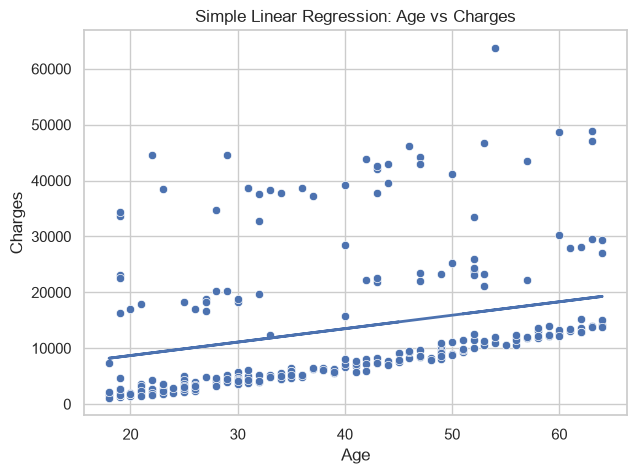

In [22]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x=X_age_test["age"], y=y_age_test)
plt.plot(
    X_age_test["age"],
    simple_pred,
    linewidth=2
)
plt.xlabel("Age")
plt.ylabel("Charges")
plt.title("Simple Linear Regression: Age vs Charges")
plt.show()

## **2. Multiple Linear Regression**

Multiple linear regression uses all available demographic and lifestyle predictors.

The preprocessing and regression model are combined in a single pipeline to ensure consistent transformations.

In [23]:
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

In [24]:
def evaluate_model(name, y_true, y_pred):
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

results = [
    evaluate_model("Simple Linear Regression", y_age_test, simple_pred),
    evaluate_model("Multiple Linear Regression", y_test, linear_pred)
]

pd.DataFrame(results)

,Model,MAE,RMSE,R2
0,Simple Linear Regression,9173.258197,11661.215952,0.124090
1,Multiple Linear Regression,4181.194474,5796.284659,0.783593


## **3. Analyze Relationships Between Variables**

Relationships between predictors and healthcare charges are examined using correlation analysis and grouped visualizations.

Correlation measures linear association and should not be interpreted as proof of causation.

In [25]:
print("Correlation with charges:")
display(
    df.select_dtypes(include=np.number)
      .corr()["charges"]
      .sort_values(ascending=False)
      .to_frame("Correlation")
)

Correlation with charges:


,Correlation
charges,1.000000
age,0.299008
bmi,0.198341
children,0.067998


In [26]:
for col in ["smoker", "sex", "region"]:
    display(
        df.groupby(col)["charges"]
          .agg(["count", "mean", "median"])
          .sort_values("mean", ascending=False)
    )

,count,mean,median
smoker,,,
yes,274,32050.231832,34456.34845
no,1064,8434.268298,7345.40530


,count,mean,median
sex,,,
male,676,13956.751178,9369.61575
female,662,12569.578844,9412.96250


,count,mean,median
region,,,
southeast,364,14735.411438,9294.131950
northeast,324,13406.384516,10057.652025
northwest,325,12417.575374,8965.795750
southwest,325,12346.937377,8798.593000


## **4.Check Assumptions of Linear Regression**

Important regression assumptions include:

- Linearity
- Approximately constant residual variance
- Approximately normal residual distribution
- Limited multicollinearity
- Independent observations

Residual plots and statistical diagnostics are used to assess these assumptions.

The Breusch-Pagan test is used to examine heteroscedasticity, while VIF is used to examine multicollinearity. :contentReference[oaicite:5]{index=5}

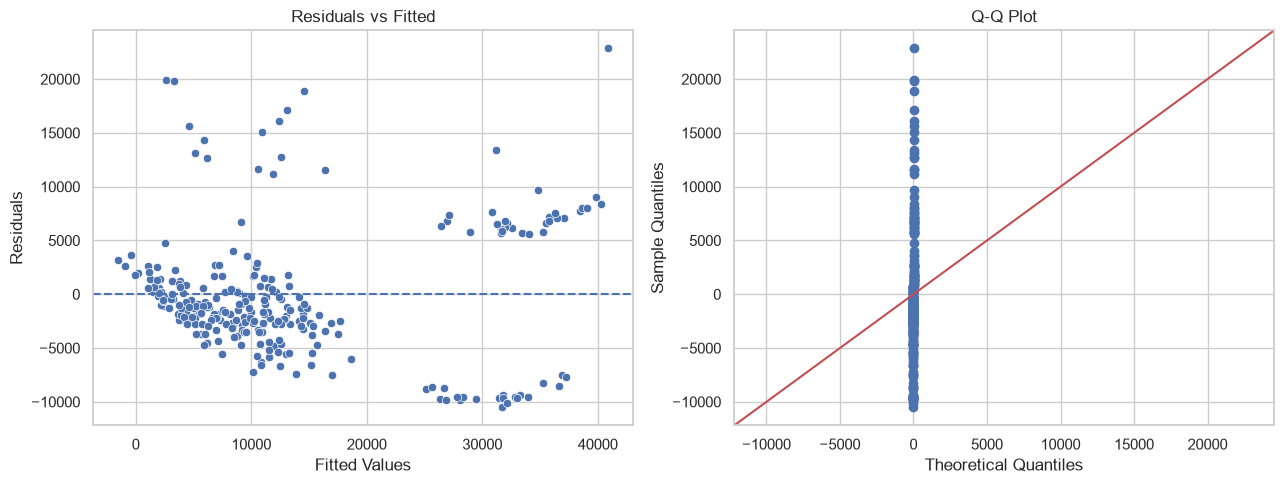

In [27]:
residuals = y_test - linear_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(x=linear_pred, y=residuals, ax=axes[0])
axes[0].axhline(0, linestyle="--")
axes[0].set_xlabel("Fitted Values")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Fitted")

sm.qqplot(residuals, line="45", ax=axes[1])
axes[1].set_title("Q-Q Plot")

plt.tight_layout()
plt.show()

In [28]:
X_test_encoded = preprocessor.fit(X_train, y_train).transform(X_test)
X_bp = sm.add_constant(X_test_encoded.toarray() if hasattr(X_test_encoded, "toarray") else X_test_encoded)

bp = het_breuschpagan(residuals, X_bp)

print("Breusch-Pagan p-value:", bp[1])

Breusch-Pagan p-value: 0.00028175969037638363


In [29]:
vif_data = sm.add_constant(df[numeric_features].dropna())

vif = pd.DataFrame({
    "Feature": vif_data.columns,
    "VIF": [
        variance_inflation_factor(vif_data.values, i)
        for i in range(vif_data.shape[1])
    ]
})

display(vif)

,Feature,VIF
0,const,31.954929
1,age,1.013816
2,bmi,1.012152
3,children,1.001874


## **5. Polynomial Regression**

Healthcare costs may not have purely linear relationships with all numerical predictors.

A degree-2 polynomial transformation is therefore applied to the numerical variables while categorical variables continue to use one-hot encoding.

Polynomial features create squared and interaction terms, allowing the linear regression estimator to represent nonlinear relationships. :contentReference[oaicite:6]{index=6}

In [30]:
poly_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("scaler", StandardScaler())
    ]), numeric_features),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

poly_model = Pipeline([
    ("preprocessor", poly_preprocessor),
    ("model", LinearRegression())
])

poly_model.fit(X_train, y_train)
poly_pred = poly_model.predict(X_test)

poly_result = evaluate_model("Polynomial Regression", y_test, poly_pred)
poly_result

{'Model': 'Polynomial Regression',
 'MAE': 4254.2748268291825,
 'RMSE': np.float64(5841.28018590557),
 'R2': 0.7802200772760515}

# **Part 3 — Regularization**

Regularization controls model complexity by penalizing large regression coefficients.

Two regularized models are implemented:

- **Ridge Regression** — L2 regularization
- **Lasso Regression** — L1 regularization

Regularization can reduce sensitivity to multicollinearity and help control overfitting.

In [31]:
ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=10))
])

ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)

ridge_result = evaluate_model("Ridge Regression", y_test, ridge_pred)
ridge_result

{'Model': 'Ridge Regression',
 'MAE': 4238.823916708755,
 'RMSE': np.float64(5821.591697020547),
 'R2': 0.7816991510258207}

In [32]:
lasso_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Lasso(alpha=100, max_iter=10000))
])

lasso_model.fit(X_train, y_train)
lasso_pred = lasso_model.predict(X_test)

lasso_result = evaluate_model("Lasso Regression", y_test, lasso_pred)
lasso_result

{'Model': 'Lasso Regression',
 'MAE': 4246.628847310126,
 'RMSE': np.float64(5852.362078145381),
 'R2': 0.779385367180736}

# **Part 4 — Model Evaluation**

The regression models are compared using:

- **MAE** — average absolute prediction error.
- **RMSE** — penalizes larger errors more strongly.
- **R²** — proportion of target variance explained by the model.

For MAE and RMSE, lower values indicate smaller prediction errors. For R², higher values indicate greater explained variance.

In [33]:
results = pd.DataFrame([
    evaluate_model("Simple Linear Regression", y_age_test, simple_pred),
    evaluate_model("Multiple Linear Regression", y_test, linear_pred),
    poly_result,
    ridge_result,
    lasso_result
])

results.sort_values("RMSE")

,Model,MAE,RMSE,R2
1,Multiple Linear Regression,4181.194474,5796.284659,0.783593
3,Ridge Regression,4238.823917,5821.591697,0.781699
2,Polynomial Regression,4254.274827,5841.280186,0.780220
4,Lasso Regression,4246.628847,5852.362078,0.779385
0,Simple Linear Regression,9173.258197,11661.215952,0.124090


In [34]:
models = {
    "Multiple Linear": (linear_model, X_train, X_test, y_train, y_test),
    "Polynomial": (poly_model, X_train, X_test, y_train, y_test),
    "Ridge": (ridge_model, X_train, X_test, y_train, y_test),
    "Lasso": (lasso_model, X_train, X_test, y_train, y_test)
}

overfit = []

for name, (model, Xtr, Xte, ytr, yte) in models.items():
    overfit.append({
        "Model": name,
        "Train R2": r2_score(ytr, model.predict(Xtr)),
        "Test R2": r2_score(yte, model.predict(Xte))
    })

pd.DataFrame(overfit)

,Model,Train R2,Test R2
0,Multiple Linear,0.741726,0.783593
1,Polynomial,0.748013,0.780220
2,Ridge,0.741214,0.781699
3,Lasso,0.740514,0.779385


##  **Overfitting Analysis**

A substantial gap between training and testing performance can indicate overfitting.

The final model should therefore be judged primarily on unseen test data rather than training performance alone.

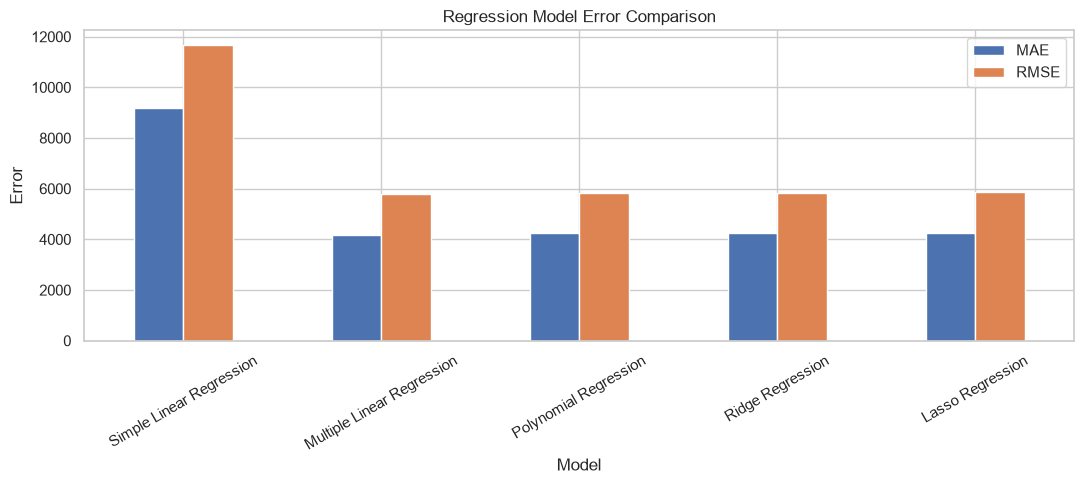

In [35]:
plot_df = results.set_index("Model")[["MAE", "RMSE"]]

plot_df.plot(kind="bar", figsize=(11, 5))
plt.ylabel("Error")
plt.title("Regression Model Error Comparison")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## **Best Regression Model**

The final regression model is selected based on test-set performance.

The selection focuses primarily on low RMSE and MAE while also considering R² and the model's generalization behavior.

In [36]:
best_model_name = results.sort_values(
    ["RMSE", "MAE"]
).iloc[0]["Model"]

print("Selected model based on test RMSE and MAE:", best_model_name)

Selected model based on test RMSE and MAE: Multiple Linear Regression


In [37]:
coef_model = linear_model.named_steps["model"]
feature_names = linear_model.named_steps["preprocessor"].get_feature_names_out()

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coef_model.coef_
})

display(
    coef_df.assign(AbsCoefficient=lambda x: x["Coefficient"].abs())
           .sort_values("AbsCoefficient", ascending=False)
           .head(15)
)

,Feature,Coefficient,AbsCoefficient
6,cat__smoker_yes,11825.564428,11825.564428
5,cat__smoker_no,-11825.564428,11825.564428
0,num__age,3614.975415,3614.975415
1,num__bmi,2036.228123,2036.228123
2,num__children,516.890247,516.890247
7,cat__region_northeast,459.585244,459.585244
10,cat__region_southwest,-350.214110,350.214110
9,cat__region_southeast,-198.279052,198.279052
8,cat__region_northwest,88.907918,88.907918
4,cat__sex_male,-9.295846,9.295846


The regression coefficients provide an interpretable view of how individual encoded features are associated with predicted healthcare charges, holding the other model features constant.

Coefficient interpretation should be treated as an association within the fitted model rather than proof of causation.

# **Part 5. Clustering**

Regression predicts healthcare charges, whereas clustering addresses a different question:

**Which patients have similar overall profiles?**

Patient segmentation is performed using K-Means and hierarchical clustering.

For clustering, the target variable is included because the project specifically aims to identify high-cost patient groups as part of the segmentation analysis.

All clustering variables are standardized so that variables measured on different numerical scales do not dominate the distance calculation.

In [38]:
cluster_features = numeric_features + [target] + categorical_features

cluster_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features + [target]),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]), categorical_features)
])

X_cluster = cluster_preprocessor.fit_transform(df[cluster_features])

print("Clustering matrix shape:", X_cluster.shape)

Clustering matrix shape: (1338, 12)


## **1. Determine Optimal Number of Clusters**

The silhouette score is calculated for multiple values of K.

A higher silhouette score indicates better separation and cohesion of the resulting clusters.

In [39]:
k_scores = []

for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster)
    k_scores.append({
        "K": k,
        "Inertia": km.inertia_,
        "Silhouette": silhouette_score(X_cluster, labels)
    })

k_scores = pd.DataFrame(k_scores)
display(k_scores)

,K,Inertia,Silhouette
0,2,6143.438139,0.237944
1,3,5196.240369,0.178067
2,4,4472.471342,0.198240
3,5,4085.641864,0.185029
4,6,3846.387836,0.159857
5,7,3650.632731,0.159656
6,8,3474.006737,0.155016


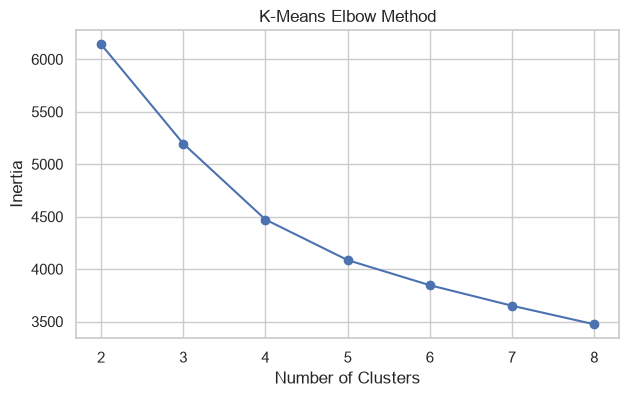

In [40]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(k_scores["K"], k_scores["Inertia"], marker="o")
ax.set_xlabel("Number of Clusters")
ax.set_ylabel("Inertia")
ax.set_title("K-Means Elbow Method")
plt.show()

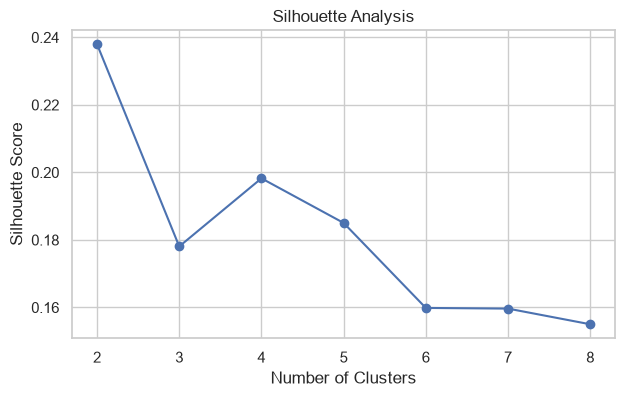

Selected K based on highest silhouette score: 2


In [41]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(k_scores["K"], k_scores["Silhouette"], marker="o")
ax.set_xlabel("Number of Clusters")
ax.set_ylabel("Silhouette Score")
ax.set_title("Silhouette Analysis")
plt.show()

best_k = int(
    k_scores.loc[k_scores["Silhouette"].idxmax(), "K"]
)

print("Selected K based on highest silhouette score:", best_k)

In [42]:
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)

df["kmeans_cluster"] = kmeans.fit_predict(X_cluster)

print(df["kmeans_cluster"].value_counts().sort_index())

kmeans_cluster
0     270
1    1068
Name: count, dtype: int64


In [43]:
cluster_profile = df.groupby("kmeans_cluster").agg(
    Size=("charges", "size"),
    Avg_Age=("age", "mean"),
    Avg_BMI=("bmi", "mean"),
    Avg_Children=("children", "mean"),
    Avg_Charges=("charges", "mean"),
    Smoker_Rate=("smoker", lambda x: (x == "yes").mean())
).round(2)

display(cluster_profile)

,Size,Avg_Age,Avg_BMI,Avg_Children,Avg_Charges,Smoker_Rate
kmeans_cluster,,,,,,
0,270,41.94,31.77,1.23,33719.66,0.89
1,1068,38.52,30.38,1.06,8100.67,0.03


## **2. High-Cost Patient Groups**

Cluster-level average charges are compared to identify segments associated with relatively high healthcare costs.

The cluster profile also examines age, BMI, number of children, and smoking prevalence to understand the characteristics of each segment.

In [44]:
cluster_profile.sort_values("Avg_Charges", ascending=False)

,Size,Avg_Age,Avg_BMI,Avg_Children,Avg_Charges,Smoker_Rate
kmeans_cluster,,,,,,
0,270,41.94,31.77,1.23,33719.66,0.89
1,1068,38.52,30.38,1.06,8100.67,0.03


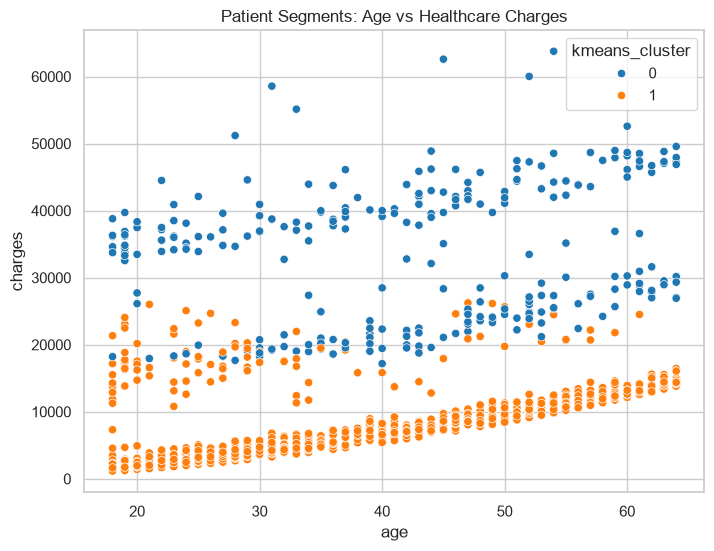

In [45]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="age",
    y="charges",
    hue="kmeans_cluster",
    palette="tab10"
)

plt.title("Patient Segments: Age vs Healthcare Charges")
plt.show()

## **3 Hierarchical Clustering**

Hierarchical clustering creates a hierarchy of observations by progressively merging similar groups.

An agglomerative approach with Ward linkage is used. Ward linkage minimizes within-cluster variance and uses Euclidean distance. :contentReference[oaicite:7]{index=7}

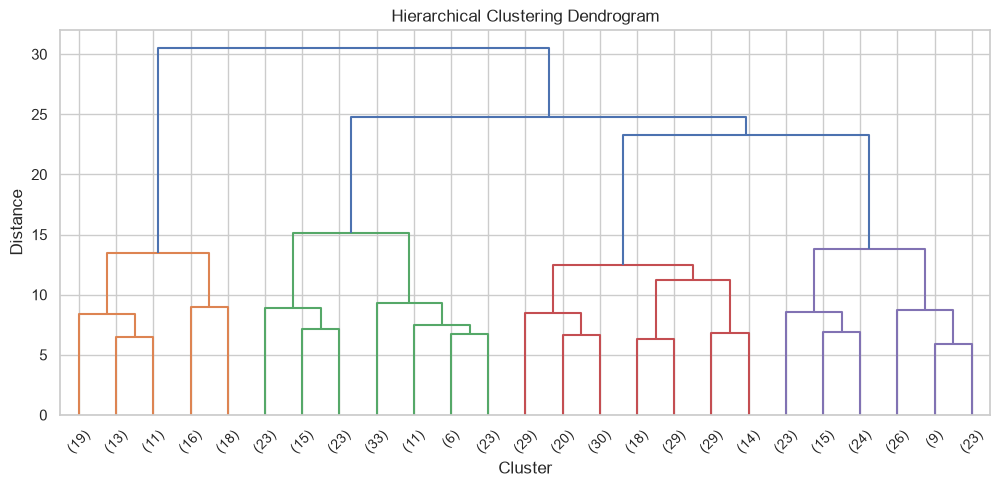

In [46]:
sample_size = min(500, len(X_cluster))
sample_idx = np.random.RandomState(42).choice(
    len(X_cluster), sample_size, replace=False
)

X_hier = X_cluster[sample_idx]

Z = linkage(X_hier, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=25)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Cluster")
plt.ylabel("Distance")
plt.show()

## **4. Compare Clustering Approaches**

K-Means and hierarchical clustering are compared using silhouette score.

K-Means is useful when a fixed number of compact clusters is required, while hierarchical clustering provides a tree-based view of how observations merge into groups.

In [48]:
kmeans_silhouette = silhouette_score(X_cluster, df["kmeans_cluster"])

comparison = pd.DataFrame({
    "Method": ["K-Means", "Hierarchical"],
    "Silhouette": [
        kmeans_silhouette,
        silhouette_score(X_hier, hier_labels)
    ]
})

display(comparison)

,Method,Silhouette
0,K-Means,0.237944
1,Hierarchical,0.250845


In [49]:
for cluster in sorted(df["kmeans_cluster"].unique()):
    subset = df[df["kmeans_cluster"] == cluster]

    print(f"\nCluster {cluster}")
    print("-" * 30)
    print(f"Patients: {len(subset)}")
    print(f"Average age: {subset['age'].mean():.1f}")
    print(f"Average BMI: {subset['bmi'].mean():.1f}")
    print(f"Average charges: ${subset['charges'].mean():,.0f}")
    print(f"Smoker rate: {(subset['smoker'] == 'yes').mean():.1%}")


Cluster 0
------------------------------
Patients: 270
Average age: 41.9
Average BMI: 31.8
Average charges: $33,720
Smoker rate: 88.5%

Cluster 1
------------------------------
Patients: 1068
Average age: 38.5
Average BMI: 30.4
Average charges: $8,101
Smoker rate: 3.3%


# **Part 6 — Insights and Interpretation**

The final stage converts model outputs into understandable data-science findings.

The interpretation focuses on:

1. Factors associated with healthcare cost.
2. Characteristics of relatively high-cost patient groups.
3. Differences between clustering approaches.
4. Practical implications for healthcare cost analysis.

The insights below should be based on the actual values produced by the notebook rather than assumptions made before model execution.

In [50]:
high_cost_cluster = cluster_profile["Avg_Charges"].idxmax()
low_cost_cluster = cluster_profile["Avg_Charges"].idxmin()

smoker_cost = df.groupby("smoker")["charges"].mean()
region_cost = df.groupby("region")["charges"].mean()

print("Highest-cost cluster:", high_cost_cluster)
print(f"Average charges: ${cluster_profile.loc[high_cost_cluster, 'Avg_Charges']:,.2f}")

print("\nLowest-cost cluster:", low_cost_cluster)
print(f"Average charges: ${cluster_profile.loc[low_cost_cluster, 'Avg_Charges']:,.2f}")

print("\nAverage charges by smoking status:")
display(smoker_cost.sort_values(ascending=False))

print("\nAverage charges by region:")
display(region_cost.sort_values(ascending=False))

Highest-cost cluster: 0
Average charges: $33,719.66

Lowest-cost cluster: 1
Average charges: $8,100.67

Average charges by smoking status:


smoker
yes    32050.231832
no      8434.268298
Name: charges, dtype: float64


Average charges by region:


region
southeast    14735.411438
northeast    13406.384516
northwest    12417.575374
southwest    12346.937377
Name: charges, dtype: float64

# **Final Conclusions**


### **Healthcare Cost Prediction**

The regression models provide a quantitative way to estimate individual healthcare charges from demographic and lifestyle variables.

Model comparison should be based on the test-set MAE, RMSE, and R² values generated above.

### **Important Factors**

The coefficient analysis and grouped exploratory analysis identify the variables most strongly associated with predicted healthcare charges.

These relationships represent statistical associations in the dataset and should not automatically be interpreted as causal effects.

### **High-Cost Patient Groups**

The clustering analysis identifies patient segments with different average healthcare charges.

The highest-cost segment can be examined using its average age, BMI, smoking rate, number of dependents, and other available characteristics.

### **Patient Segmentation**

K-Means provides a compact segmentation based on standardized patient characteristics, while hierarchical clustering provides a complementary view of similarity between observations.

### **Business Value**

The workflow can support:

- Healthcare cost forecasting
- Risk profiling
- Patient segment analysis
- Resource planning
- Identification of relatively high-cost patient groups
- Data-driven insurance analysis

## **Final Takeaway**

This project demonstrates an end-to-end machine learning workflow combining supervised learning for healthcare cost prediction with unsupervised learning for patient segmentation.

The most important lesson is that model performance should be evaluated on unseen data, while model assumptions and cluster characteristics should be examined before drawing practical conclusions.

# **Project Summary**

| Component | Technique | Purpose |
|---|---|---|
| Missing Values | Simple Imputation | Basic data cleaning |
| Missing Values | KNN Imputation | Advanced numerical imputation |
| Encoding | One-Hot Encoding | Convert categorical variables |
| Scaling | StandardScaler | Put numerical features on comparable scales |
| Baseline Model | Simple Linear Regression | Understand basic relationship |
| Main Model | Multiple Linear Regression | Predict healthcare charges |
| Nonlinear Model | Polynomial Regression | Capture nonlinear relationships |
| Regularization | Ridge | Control coefficient magnitude |
| Regularization | Lasso | Regularization and coefficient shrinkage |
| Evaluation | MAE, RMSE, R² | Compare predictive performance |
| Diagnostics | Residuals, Q-Q, BP Test, VIF | Check regression assumptions |
| Segmentation | K-Means | Patient clustering |
| Cluster Selection | Elbow + Silhouette | Select cluster count |
| Segmentation | Hierarchical Clustering | Alternative clustering approach |
| Interpretation | Cluster Profiles | Understand patient groups |